In [1]:
import pathlib, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 9})

FC        = 5.0
FIR_ORDEN = 20
VENTANA   = "hamming"
IIR_ORDEN = 2
T_DESCARTE = 1.0
EJE       = "auto"
FC_ALT    = [2.0, 10.0]
REGISTROS = {"R1": "Motor apagado", "R2": "Perturbación baja", "R3": "Perturbación alta"}
LSB_POR_G_DEFECTO = 16384.0

def _raiz():
    p = pathlib.Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "datos").is_dir() and (c / "analisis").is_dir():
            return c
    return p
RAIZ = _raiz()
DATOS = RAIZ / "datos"
SALIDA = RAIZ / "resultados"
SALIDA.mkdir(exist_ok=True)
if not (DATOS / "R1.csv").exists():
    raise SystemExit(f"No se encontraron los registros en {DATOS}")
print("Carpeta de datos:", DATOS)

Carpeta de datos: /home/claude/PDS_Proyecto2/datos


In [2]:
def leer_csv(ruta):
    meta = {}
    with open(ruta, encoding="utf-8", errors="replace") as f:
        for linea in f:
            if not linea.startswith("#"):
                break
            for k, v in re.findall(r"(\w+)=([^\s]+)", linea):
                meta.setdefault(k, v)
    df = pd.read_csv(ruta, comment="#")
    return df, meta

crudos, metas = {}, {}
for r in REGISTROS:
    crudos[r], metas[r] = leer_csv(DATOS / f"{r}.csv")

filas = []
for r, df in crudos.items():
    t = df["t_us"].to_numpy() / 1e6
    dt = np.diff(t)
    fs_meta = float(metas[r].get("fs_hz", np.nan))
    filas.append({"Registro": r, "Condición": REGISTROS[r], "Muestras": len(df),
                  "Duración [s]": round(t[-1] - t[0] + np.median(dt), 3),
                  "fs declarada [Hz]": fs_meta, "fs medida [Hz]": round(1 / dt.mean(), 3),
                  "dt máx [ms]": round(dt.max() * 1e3, 3),
                  "Muestras perdidas (dt>1.5Ts)": int((dt > 1.5 / fs_meta).sum())})
tabla_adq = pd.DataFrame(filas)
display(tabla_adq) if "display" in globals() else print(tabla_adq.to_string(index=False))

FS = float(np.median([float(metas[r].get("fs_hz", 1 / np.diff(crudos[r]["t_us"]).mean() * 1e6))
                      for r in REGISTROS]))
LSB_POR_G = float(metas["R1"].get("lsb_por_g", LSB_POR_G_DEFECTO))
K0 = int(round(T_DESCARTE * FS))

if EJE == "auto":
    medias_R1 = {e: crudos["R1"][f"{e}_raw"].mean() for e in ("ax", "ay", "az")}
    EJE = max(medias_R1, key=lambda e: abs(medias_R1[e]))
print(f"fs = {FS} Hz | eje analizado = {EJE} | escala = {LSB_POR_G} LSB/g | descarte = {K0} muestras")

X = {r: crudos[r][f"{EJE}_raw"].to_numpy(dtype=float) / LSB_POR_G for r in REGISTROS}
for r in REGISTROS:
    print(f"{r}: media = {X[r].mean():+.5f} g   desviación = {X[r].std() * 1e3:.3f} mg")

Registro         Condición  Muestras  Duración [s]  fs declarada [Hz]  fs medida [Hz]  dt máx [ms]  Muestras perdidas (dt>1.5Ts)
      R1     Motor apagado      2000          20.0              100.0           100.0       10.001                             0
      R2 Perturbación baja      2000          20.0              100.0           100.0       10.001                             0
      R3 Perturbación alta      2000          20.0              100.0           100.0       10.001                             0
fs = 100.0 Hz | eje analizado = az | escala = 16384.0 LSB/g | descarte = 100 muestras
R1: media = +0.93880 g   desviación = 1.756 mg
R2: media = +0.93861 g   desviación = 30.796 mg
R3: media = +0.93846 g   desviación = 24.977 mg


In [3]:
def potencias(x):
    m = np.mean(x)
    return m ** 2, np.mean((x - m) ** 2)

def snr_db(x):
    ps, pn = potencias(x)
    return 10 * np.log10(ps / pn)

filas = []
for r in REGISTROS:
    ps, pn = potencias(X[r])
    filas.append({"Registro": r, "Condición": REGISTROS[r], "media [g]": X[r].mean(),
                  "P_s [g²]": ps, "P_n [g²]": pn, "σ_n [mg]": np.sqrt(pn) * 1e3,
                  "SNR entrada completa [dB]": snr_db(X[r]),
                  "SNR entrada t≥1 s [dB]": snr_db(X[r][K0:])})
tabla_snr_in = pd.DataFrame(filas)
print(tabla_snr_in.to_string(index=False, float_format=lambda v: f"{v:.6g}"))

filas = []
for r in REGISTROS:
    fila = {"Registro": r}
    for e in ("ax", "ay", "az"):
        x = crudos[r][f"{e}_raw"].to_numpy(float) / LSB_POR_G
        fila[f"{e} media [g]"] = round(x.mean(), 4)
        fila[f"SNR {e} [dB]"] = round(snr_db(x), 2)
    filas.append(fila)
tabla_ejes = pd.DataFrame(filas)
print("\nSNR por eje:\n" + tabla_ejes.to_string(index=False))

Registro         Condición  media [g]  P_s [g²]    P_n [g²]  σ_n [mg]  SNR entrada completa [dB]  SNR entrada t≥1 s [dB]
      R1     Motor apagado   0.938803  0.881351 3.08241e-06   1.75568                    54.5626                 54.5377
      R2 Perturbación baja   0.938606  0.880981  0.00094839   30.7959                    29.6798                 29.6718
      R3 Perturbación alta   0.938465  0.880716  0.00062386   24.9772                    31.4975                 31.4621

SNR por eje:
Registro  ax media [g]  SNR ax [dB]  ay media [g]  SNR ay [dB]  az media [g]  SNR az [dB]
      R1       -0.0938        39.07        0.0043        11.56        0.9388        54.56
      R2       -0.0937        14.27        0.0041       -10.34        0.9386        29.68
      R3       -0.0935        10.89        0.0038       -22.04        0.9385        31.50


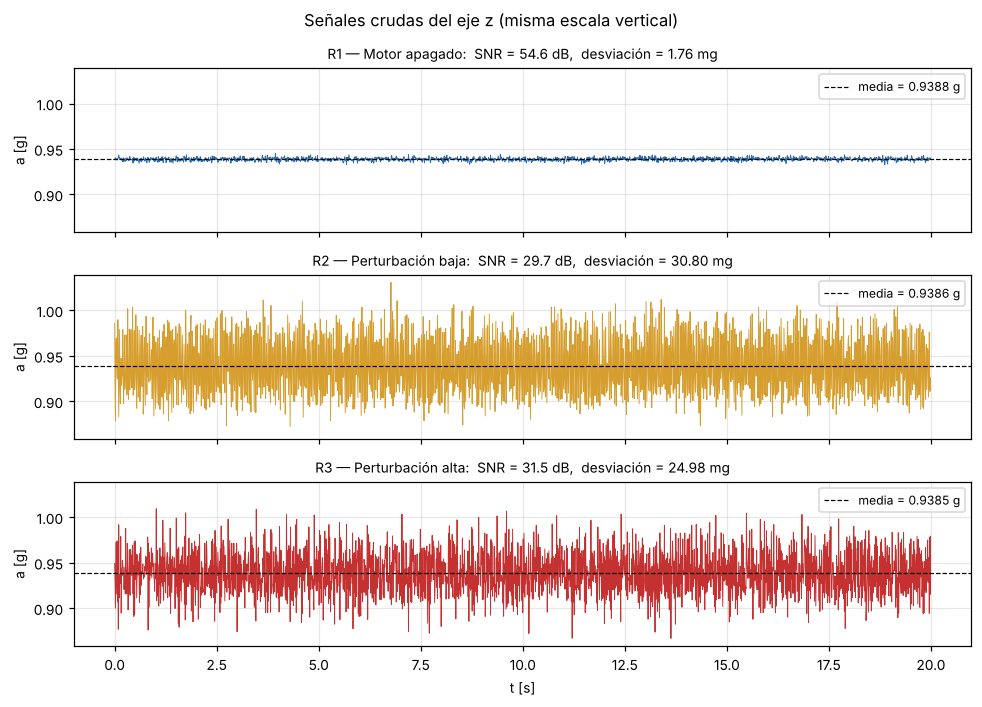

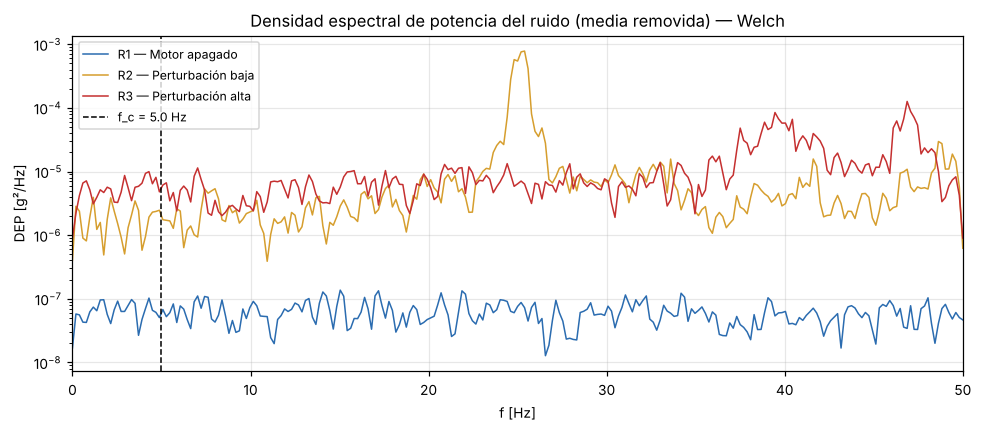

Registro  % P_n bajo 2 Hz  % P_n bajo 5 Hz  % P_n bajo 10 Hz  Pico dominante [Hz]
      R1              4.0             10.4              20.7                15.04
      R2              0.4              0.9               2.2                25.39
      R3              1.4              4.3               7.8                46.88


In [4]:
colores = {"R1": "#2b6cb0", "R2": "#d69e2e", "R3": "#c53030"}
fig, ax = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, sharey=True)
for i, r in enumerate(REGISTROS):
    t = np.arange(X[r].size) / FS
    ax[i].plot(t, X[r], lw=0.6, color=colores[r])
    ax[i].axhline(X[r].mean(), color="k", lw=0.8, ls="--", label=f"media = {X[r].mean():.4f} g")
    ax[i].set_ylabel("a [g]")
    ax[i].set_title(f"{r} — {REGISTROS[r]}:  SNR = {snr_db(X[r]):.1f} dB,  desviación = {X[r].std()*1e3:.2f} mg", fontsize=9)
    ax[i].legend(loc="upper right", fontsize=8)
ax[-1].set_xlabel("t [s]")
fig.suptitle(f"Señales crudas del eje {EJE[-1]} (misma escala vertical)")
fig.tight_layout(); fig.savefig(SALIDA / "fig1_senales_crudas.png"); plt.show()

def psd(x):
    f, p = signal.welch(x - np.mean(x), fs=FS, nperseg=512, window="hann")
    return f, p

fig, ax = plt.subplots(figsize=(9, 4))
for r in REGISTROS:
    f, p = psd(X[r])
    ax.semilogy(f, p, color=colores[r], lw=1, label=f"{r} — {REGISTROS[r]}")
ax.axvline(FC, color="k", ls="--", lw=1, label=f"f_c = {FC} Hz")
ax.set_xlabel("f [Hz]"); ax.set_ylabel("DEP [g²/Hz]"); ax.set_xlim(0, FS / 2)
ax.set_title("Densidad espectral de potencia del ruido (media removida) — Welch")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(SALIDA / "fig2_espectro_entrada.png"); plt.show()

filas = []
for r in REGISTROS:
    f, p = psd(X[r])
    total = np.trapezoid(p, f)
    fila = {"Registro": r}
    for fc in sorted({FC, *FC_ALT}):
        fila[f"% P_n bajo {fc:g} Hz"] = round(100 * np.trapezoid(p[f <= fc], f[f <= fc]) / total, 1)
    fila["Pico dominante [Hz]"] = round(f[np.argmax(p[1:]) + 1], 2)
    filas.append(fila)
tabla_fc = pd.DataFrame(filas)
print(tabla_fc.to_string(index=False))

In [5]:
def disenar(fc, fs=FS):
    b_fir = signal.firwin(FIR_ORDEN + 1, fc, window=VENTANA, fs=fs)
    b_iir, a_iir = signal.butter(IIR_ORDEN, fc, btype="low", fs=fs)
    return b_fir, np.array([1.0]), b_iir, a_iir

B_FIR, A_FIR, B_IIR, A_IIR = disenar(FC)

print("FIR — coeficientes b_k (simétricos -> fase lineal):")
for k, b in enumerate(B_FIR):
    print(f"  b[{k:2d}] = {b:+.8f}")
print(f"  Σ b_k = {B_FIR.sum():.10f}  (ganancia en DC = 1)")
print(f"  ¿Simétrico? {np.allclose(B_FIR, B_FIR[::-1])}")

print("\nIIR Butterworth — coeficientes:")
print("  b =", np.array2string(B_IIR, precision=10))
print("  a =", np.array2string(A_IIR, precision=10))
print(f"  Ganancia en DC = Σb/Σa = {B_IIR.sum() / A_IIR.sum():.10f}")
print("\nEcuación en diferencias IIR:")
print(f"  y[n] = {B_IIR[0]:.8f} x[n] + {B_IIR[1]:.8f} x[n-1] + {B_IIR[2]:.8f} x[n-2]"
      f" {-A_IIR[1]:+.8f} y[n-1] {-A_IIR[2]:+.8f} y[n-2]")

polos = np.roots(A_IIR)
ceros = np.roots(B_IIR)
print("\nPolos IIR:")
for p in polos:
    print(f"  p = {p.real:+.6f} {p.imag:+.6f}j   |p| = {abs(p):.6f}   ∠p = {np.degrees(np.angle(p)):+.3f}°")
print("Ceros IIR:", np.round(ceros, 6))
ESTABLE_IIR = bool(np.all(np.abs(polos) < 1))
print(f"Estabilidad IIR: todos los |p| < 1 -> {ESTABLE_IIR}")
print("Estabilidad FIR: sin realimentación; sus 20 polos están en z = 0 -> siempre estable (BIBO)")

wc_pre = 2 * FS * np.tan(np.pi * FC / FS)
s_polos = wc_pre * np.exp(1j * np.pi * (2 * np.arange(1, IIR_ORDEN + 1) + IIR_ORDEN - 1) / (2 * IIR_ORDEN))
z_polos = (1 + s_polos / (2 * FS)) / (1 - s_polos / (2 * FS))
print(f"\nPrototipo analógico Butterworth: Ω_c pre-distorsionada = {wc_pre:.4f} rad/s "
      f"(vs 2πf_c = {2 * np.pi * FC:.4f})")
print("  polos en s:", np.round(s_polos, 4), " -> bilineal -> polos en z:", np.round(z_polos, 6))

pd.DataFrame({"k": range(len(B_FIR)), "b_FIR": B_FIR}).to_csv(SALIDA / "coeficientes_FIR.csv", index=False)
pd.DataFrame({"k": range(3), "b_IIR": B_IIR, "a_IIR": A_IIR}).to_csv(SALIDA / "coeficientes_IIR.csv", index=False)

FIR — coeficientes b_k (simétricos -> fase lineal):
  b[ 0] = +0.00000000
  b[ 1] = +0.00132722
  b[ 2] = +0.00465025
  b[ 3] = +0.01174980
  b[ 4] = +0.02377922
  b[ 5] = +0.04072345
  b[ 6] = +0.06115693
  b[ 7] = +0.08240367
  b[ 8] = +0.10108221
  b[ 9] = +0.11389738
  b[10] = +0.11845972
  b[11] = +0.11389738
  b[12] = +0.10108221
  b[13] = +0.08240367
  b[14] = +0.06115693
  b[15] = +0.04072345
  b[16] = +0.02377922
  b[17] = +0.01174980
  b[18] = +0.00465025
  b[19] = +0.00132722
  b[20] = +0.00000000
  Σ b_k = 1.0000000000  (ganancia en DC = 1)
  ¿Simétrico? True

IIR Butterworth — coeficientes:
  b = [0.0200833656 0.0401667311 0.0200833656]
  a = [ 1.           -1.5610180758  0.6413515381]
  Ganancia en DC = Σb/Σa = 1.0000000000

Ecuación en diferencias IIR:
  y[n] = 0.02008337 x[n] + 0.04016673 x[n-1] + 0.02008337 x[n-2] +1.56101808 y[n-1] -0.64135154 y[n-2]

Polos IIR:
  p = +0.780509 +0.179324j   |p| = 0.800844   ∠p = +12.939°
  p = +0.780509 -0.179324j   |p| = 0.800844   ∠

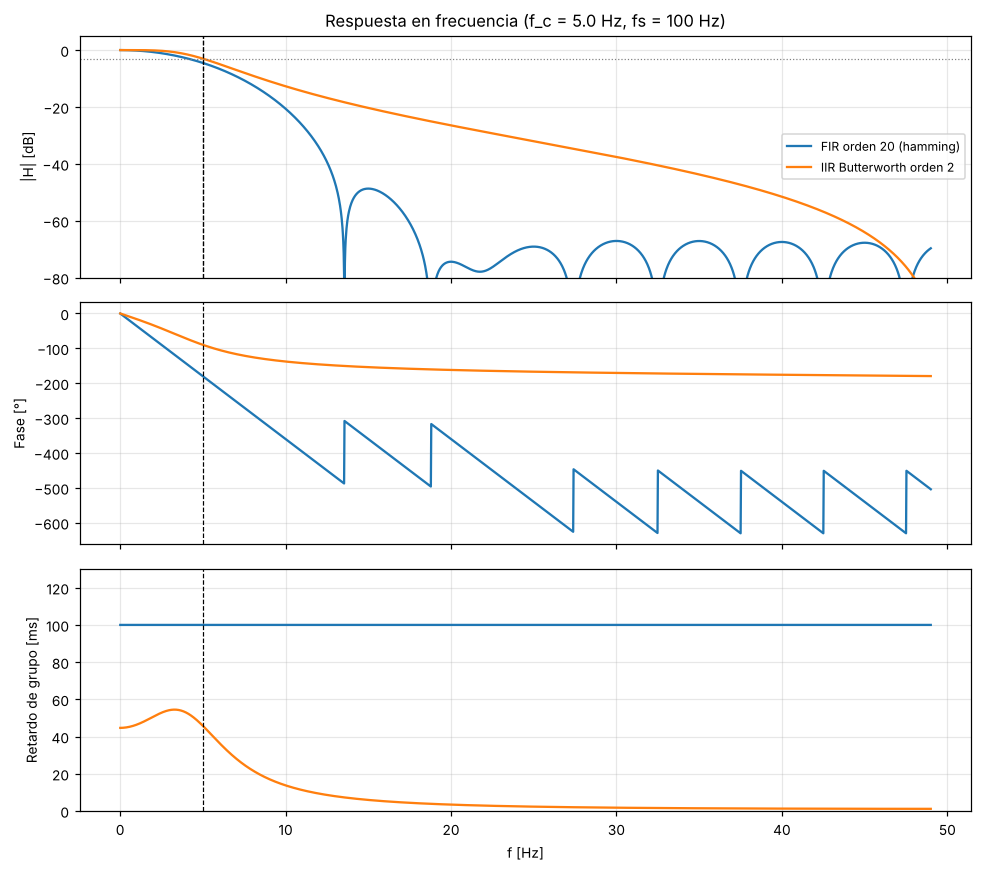

     |H| @ 1 Hz [dB]  |H| @ 5 Hz [dB]  |H| @ 10 Hz [dB]  |H| @ 14 Hz [dB]  |H| @ 20 Hz [dB]  |H| @ 30 Hz [dB]
FIR            -0.17            -4.51            -20.61            -53.46            -74.40            -67.10
IIR            -0.01            -3.01            -12.72            -18.97            -26.47            -37.56


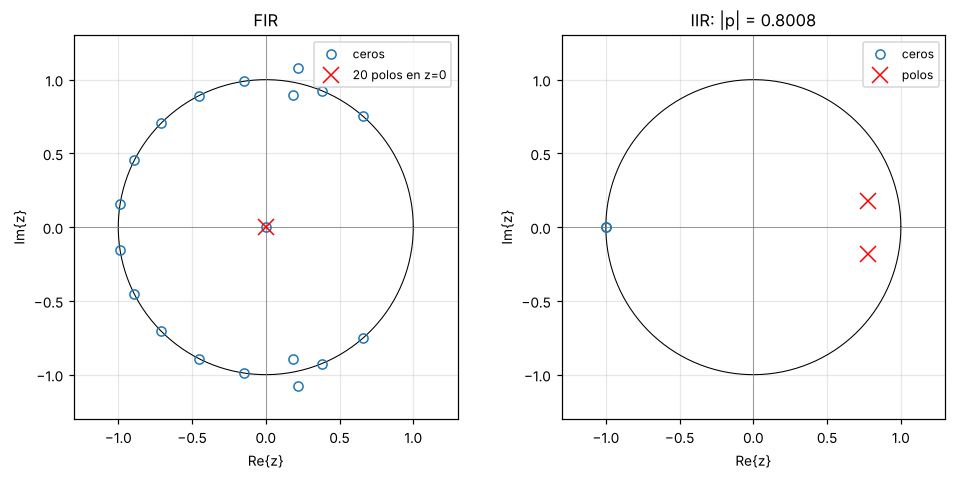

In [6]:
f = np.linspace(0.01, 0.49 * FS, 2000)
_, H_fir = signal.freqz(B_FIR, A_FIR, worN=f, fs=FS)
_, H_iir = signal.freqz(B_IIR, A_IIR, worN=f, fs=FS)
_, gd_fir = signal.group_delay((B_FIR, A_FIR), w=f, fs=FS)
_, gd_iir = signal.group_delay((B_IIR, A_IIR), w=f, fs=FS)

fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
ax[0].plot(f, 20 * np.log10(np.abs(H_fir)), label=f"FIR orden {FIR_ORDEN} ({VENTANA})")
ax[0].plot(f, 20 * np.log10(np.abs(H_iir)), label=f"IIR Butterworth orden {IIR_ORDEN}")
ax[0].axvline(FC, color="k", ls="--", lw=0.8); ax[0].axhline(-3, color="gray", ls=":", lw=0.8)
ax[0].set_ylim(-80, 5); ax[0].set_ylabel("|H| [dB]"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Respuesta en frecuencia (f_c = {FC} Hz, fs = {FS:g} Hz)")
ax[1].plot(f, np.unwrap(np.angle(H_fir)) * 180 / np.pi)
ax[1].plot(f, np.unwrap(np.angle(H_iir)) * 180 / np.pi)
ax[1].set_ylabel("Fase [°]")
ax[2].plot(f, gd_fir / FS * 1e3); ax[2].plot(f, gd_iir / FS * 1e3)
ax[2].set_ylabel("Retardo de grupo [ms]"); ax[2].set_xlabel("f [Hz]")
ax[2].set_ylim(0, max(gd_fir.max(), gd_iir[f < 15].max()) / FS * 1e3 * 1.3)
for a in ax: a.axvline(FC, color="k", ls="--", lw=0.8)
fig.tight_layout(); fig.savefig(SALIDA / "fig3_respuesta_frecuencia.png"); plt.show()

atten = {}
for nom, H in (("FIR", H_fir), ("IIR", H_iir)):
    mag = 20 * np.log10(np.abs(H))
    atten[nom] = {f"|H| @ {fx:g} Hz [dB]": round(np.interp(fx, f, mag), 2) for fx in (1, FC, 10, 14, 20, 30)}
tabla_atten = pd.DataFrame(atten).T
print(tabla_atten.to_string())

fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
th = np.linspace(0, 2 * np.pi, 400)
for a in ax:
    a.plot(np.cos(th), np.sin(th), "k", lw=0.7); a.set_aspect("equal")
    a.axhline(0, color="gray", lw=0.5); a.axvline(0, color="gray", lw=0.5)
    a.set_xlabel("Re{z}"); a.set_ylabel("Im{z}")
z_fir = np.roots(B_FIR)
ax[0].plot(z_fir.real, z_fir.imag, "o", mfc="none", label="ceros")
ax[0].plot(0, 0, "x", ms=10, color="r", label=f"{FIR_ORDEN} polos en z=0")
ax[0].set_title("FIR"); ax[0].legend(fontsize=8)
ax[1].plot(ceros.real, ceros.imag, "o", mfc="none", label="ceros")
ax[1].plot(polos.real, polos.imag, "x", ms=10, color="r", label="polos")
ax[1].set_title(f"IIR: |p| = {abs(polos[0]):.4f}"); ax[1].legend(fontsize=8)
lim = 1.3
for a in ax: a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
fig.tight_layout(); fig.savefig(SALIDA / "fig4_polos_ceros.png"); plt.show()

In [7]:
def ecuacion_diferencias(b, a, x):
    b = np.asarray(b, float); a = np.asarray(a, float)
    y = np.zeros_like(x)
    for n in range(len(x)):
        acc = 0.0
        for k in range(len(b)):
            if n - k >= 0: acc += b[k] * x[n - k]
        for k in range(1, len(a)):
            if n - k >= 0: acc -= a[k] * y[n - k]
        y[n] = acc / a[0]
    return y

for nom, (b, a) in {"FIR": (B_FIR, A_FIR), "IIR": (B_IIR, A_IIR)}.items():
    err = np.max(np.abs(ecuacion_diferencias(b, a, X["R3"]) - signal.lfilter(b, a, X["R3"])))
    print(f"{nom}: error máximo ecuación en diferencias vs lfilter = {err:.2e} g")

FIR: error máximo ecuación en diferencias vs lfilter = 5.55e-16 g
IIR: error máximo ecuación en diferencias vs lfilter = 2.00e-15 g


In [8]:
def tiempo_ejecucion(fn, rep=300):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return np.median(ts)

def retardo_escalon(b, a):
    n = int(3 * FS)
    y = signal.lfilter(b, a, np.ones(n))
    i = np.argmax(y >= 0.5)
    frac = (0.5 - y[i - 1]) / (y[i] - y[i - 1])
    return (i - 1 + frac) / FS

def retardo_xcorr(x, y):
    x = x - x.mean(); y = y - y.mean()
    c = signal.correlate(y, x, mode="full"); lags = signal.correlation_lags(len(y), len(x), mode="full")
    sel = (lags >= 0) & (lags < FS)
    return lags[sel][np.argmax(c[sel])] / FS

def ganancia_ruido_blanco(b, a):
    h = signal.lfilter(b, a, np.r_[1.0, np.zeros(4000)])
    return np.sum(h ** 2)

def analizar(fc):
    bf, af, bi, ai = disenar(fc)
    _, gdf0 = signal.group_delay((bf, af), w=[0.05], fs=FS)
    _, gdi0 = signal.group_delay((bi, ai), w=[0.05], fs=FS)
    info_filtro = {
        "FIR": dict(b=bf, a=af, orden=FIR_ORDEN, coef=len(bf), ret_teo=gdf0[0] / FS,
                    ret_esc=retardo_escalon(bf, af), estable=True, g_rb=ganancia_ruido_blanco(bf, af)),
        "IIR": dict(b=bi, a=ai, orden=IIR_ORDEN, coef=len(bi) + len(ai) - 1, ret_teo=gdi0[0] / FS,
                    ret_esc=retardo_escalon(bi, ai), estable=bool(np.all(np.abs(np.roots(ai)) < 1)),
                    g_rb=ganancia_ruido_blanco(bi, ai))}
    filas, salidas = [], {}
    for r in REGISTROS:
        x = X[r]; xv = x[K0:]
        snr_in = snr_db(xv)
        fila = {"Registro": r, "Condición": REGISTROS[r],
                "SNR ent. completa [dB]": snr_db(x), "SNR ent. [dB]": snr_in}
        for nom, d in info_filtro.items():
            y = signal.lfilter(d["b"], d["a"], x)
            salidas[(r, nom)] = y
            yv = y[K0:]
            fila[f"SNR {nom} [dB]"] = snr_db(yv)
            fila[f"ΔSNR {nom} [dB]"] = snr_db(yv) - snr_in
            fila[f"Δmedia {nom} [mg]"] = (yv.mean() - xv.mean()) * 1e3
            fila[f"σ_n {nom} [mg]"] = yv.std() * 1e3
        filas.append(fila)
    return pd.DataFrame(filas), info_filtro, salidas

tabla, INFO, Y = analizar(FC)

for nom, d in INFO.items():
    d["t_lfilter_us"] = tiempo_ejecucion(lambda: signal.lfilter(d["b"], d["a"], X["R3"])) * 1e6
    d["t_ecuacion_ms"] = tiempo_ejecucion(lambda: ecuacion_diferencias(d["b"], d["a"], X["R3"]), rep=5) * 1e3
    d["mult_por_muestra"] = len(d["b"]) + len(d["a"]) - 1

pd.options.display.float_format = "{:.3f}".format
print(tabla.to_string(index=False))

Registro         Condición  SNR ent. completa [dB]  SNR ent. [dB]  SNR FIR [dB]  ΔSNR FIR [dB]  Δmedia FIR [mg]  σ_n FIR [mg]  SNR IIR [dB]  ΔSNR IIR [dB]  Δmedia IIR [mg]  σ_n IIR [mg]
      R1     Motor apagado                  54.563         54.538        64.727         10.189           -0.004         0.545        63.679          9.141           -0.004         0.615
      R2 Perturbación baja                  29.680         29.672        50.230         20.559            0.039         2.891        48.942         19.270            0.025         3.353
      R3 Perturbación alta                  31.497         31.462        46.026         14.564           -0.004         4.689        44.920         13.458           -0.019         5.326


In [9]:
filas = []
for r in REGISTROS:
    fr = tabla.set_index("Registro").loc[r]
    for nom, d in INFO.items():
        filas.append({
            "Registro": r, "Filtro": nom,
            "SNR entrada [dB]": fr["SNR ent. [dB]"],
            "SNR salida [dB]": fr[f"SNR {nom} [dB]"],
            "ΔSNR [dB]": fr[f"ΔSNR {nom} [dB]"],
            "Δ valor medio [mg]": fr[f"Δmedia {nom} [mg]"],
            "Orden": d["orden"],
            "Mult./muestra": d["mult_por_muestra"],
            "Retardo teórico DC [ms]": d["ret_teo"] * 1e3,
            "Retardo escalón 50% [ms]": d["ret_esc"] * 1e3,
            "Tiempo lfilter [µs]": d["t_lfilter_us"],
            "Tiempo ec. dif. [ms]": d["t_ecuacion_ms"],
            "Estable": "Sí" if d["estable"] else "No",
        })
tabla_E4 = pd.DataFrame(filas)
print(tabla_E4.to_string(index=False))
tabla_E4.to_csv(SALIDA / "tabla_E4_resultados.csv", index=False, float_format="%.4f")
with open(SALIDA / "tabla_E4_resultados.md", "w", encoding="utf-8") as fmd:
    fmd.write(tabla_E4.to_markdown(index=False, floatfmt=".2f") if hasattr(tabla_E4, "to_markdown") else "")

print("\nΔSNR teórica si el ruido fuera blanco (−10·log10 Σh²):")
for nom, d in INFO.items():
    print(f"  {nom}: Σh² = {d['g_rb']:.4f}  ->  {-10 * np.log10(d['g_rb']):.2f} dB")

Registro Filtro  SNR entrada [dB]  SNR salida [dB]  ΔSNR [dB]  Δ valor medio [mg]  Orden  Mult./muestra  Retardo teórico DC [ms]  Retardo escalón 50% [ms]  Tiempo lfilter [µs]  Tiempo ec. dif. [ms] Estable
      R1    FIR            54.538           64.727     10.189              -0.004     20             21                  100.000                    95.000               32.205                 8.108      Sí
      R1    IIR            54.538           63.679      9.141              -0.004      2              5                   44.649                    40.618               12.434                 2.544      Sí
      R2    FIR            29.672           50.230     20.559               0.039     20             21                  100.000                    95.000               32.205                 8.108      Sí
      R2    IIR            29.672           48.942     19.270               0.025      2              5                   44.649                    40.618               12.434 

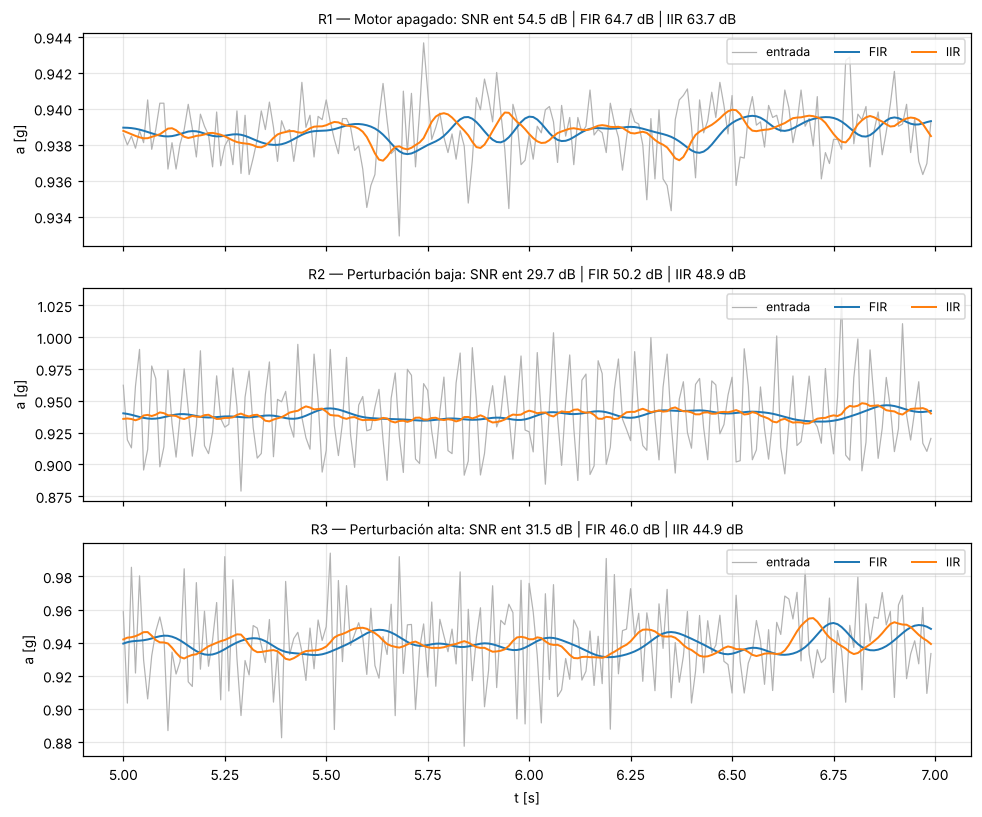

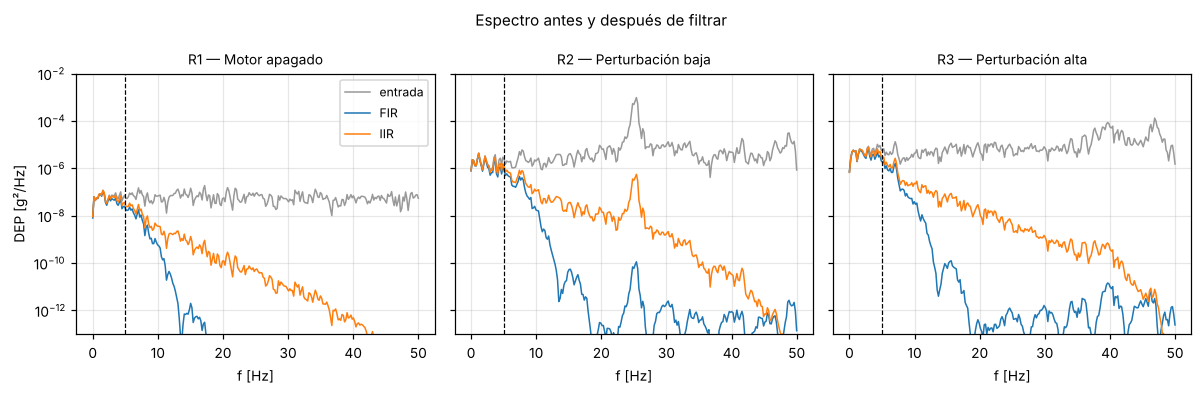

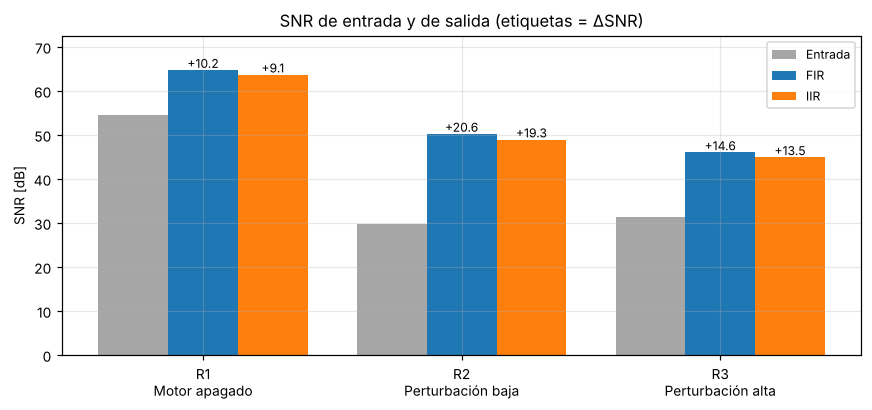

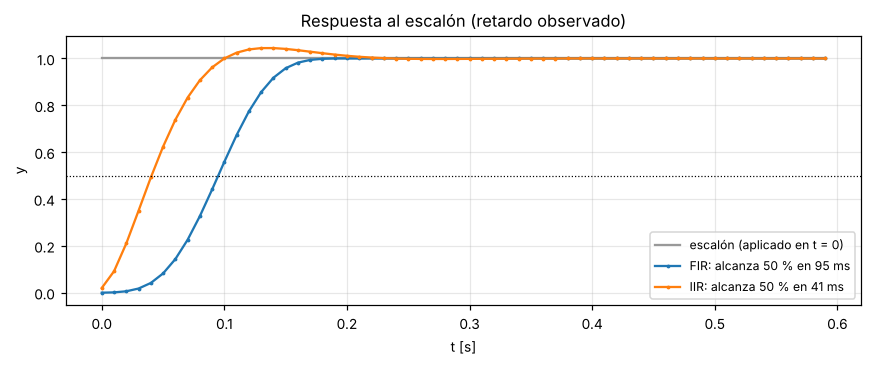

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
ventana = slice(int(5 * FS), int(7 * FS))
for i, r in enumerate(REGISTROS):
    t = np.arange(X[r].size) / FS
    ax[i].plot(t[ventana], X[r][ventana], color="0.7", lw=0.8, label="entrada")
    ax[i].plot(t[ventana], Y[(r, "FIR")][ventana], lw=1.3, label="FIR")
    ax[i].plot(t[ventana], Y[(r, "IIR")][ventana], lw=1.3, label="IIR")
    ax[i].set_ylabel("a [g]")
    fr = tabla.set_index("Registro").loc[r]
    ax[i].set_title(f"{r} — {REGISTROS[r]}: SNR ent {fr['SNR ent. [dB]']:.1f} dB | "
                    f"FIR {fr['SNR FIR [dB]']:.1f} dB | IIR {fr['SNR IIR [dB]']:.1f} dB", fontsize=9)
    ax[i].legend(fontsize=8, loc="upper right", ncol=3)
ax[-1].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(SALIDA / "fig5_tiempo_entrada_vs_salidas.png"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for i, r in enumerate(REGISTROS):
    for etiqueta, sig, kw in (("entrada", X[r][K0:], dict(color="0.6")),
                              ("FIR", Y[(r, "FIR")][K0:], {}), ("IIR", Y[(r, "IIR")][K0:], {})):
        f_, p_ = psd(sig); ax[i].semilogy(f_, p_, lw=1, label=etiqueta, **kw)
    ax[i].axvline(FC, color="k", ls="--", lw=0.8)
    ax[i].set_title(f"{r} — {REGISTROS[r]}", fontsize=9); ax[i].set_xlabel("f [Hz]")
    ax[i].set_ylim(1e-13, 1e-2)
ax[0].set_ylabel("DEP [g²/Hz]"); ax[0].legend(fontsize=8)
fig.suptitle("Espectro antes y después de filtrar", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "fig6_espectro_salidas.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
xpos = np.arange(len(REGISTROS)); w = 0.27
ax.bar(xpos - w, tabla["SNR ent. [dB]"], w, color="0.65", label="Entrada")
ax.bar(xpos, tabla["SNR FIR [dB]"], w, label="FIR")
ax.bar(xpos + w, tabla["SNR IIR [dB]"], w, label="IIR")
for i, r in enumerate(REGISTROS):
    for dx, nom in ((0, "FIR"), (w, "IIR")):
        ax.text(i + dx, tabla[f"SNR {nom} [dB]"].iloc[i] + 0.5,
                f"{tabla[f'ΔSNR {nom} [dB]'].iloc[i]:+.1f}", ha="center", fontsize=8)
ax.set_xticks(xpos, [f"{r}\n{REGISTROS[r]}" for r in REGISTROS]); ax.set_ylabel("SNR [dB]")
ax.set_ylim(0, max(tabla["SNR FIR [dB]"].max(), tabla["SNR IIR [dB]"].max()) * 1.12)
ax.set_title("SNR de entrada y de salida (etiquetas = ΔSNR)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(SALIDA / "fig7_snr_barras.png"); plt.show()

n = int(0.6 * FS); t = np.arange(n) / FS
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t, np.ones(n), color="0.6", label="escalón (aplicado en t = 0)")
for nom, d in INFO.items():
    y = signal.lfilter(d["b"], d["a"], np.ones(n))
    ax.plot(t, y, marker=".", ms=3, label=f"{nom}: alcanza 50 % en {d['ret_esc'] * 1e3:.0f} ms")
ax.axhline(0.5, color="k", ls=":", lw=0.8); ax.set_xlabel("t [s]"); ax.set_ylabel("y")
ax.set_title("Respuesta al escalón (retardo observado)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(SALIDA / "fig8_escalon_retardo.png"); plt.show()

 f_c [Hz] Filtro  Retardo DC [ms]  ΔSNR R1 [dB]  Δmedia R1 [mg]  ΔSNR R2 [dB]  Δmedia R2 [mg]  ΔSNR R3 [dB]  Δmedia R3 [mg]
    2.000    FIR          100.000        11.114          -0.004        21.532           0.039        15.633          -0.003
    2.000    IIR          112.462        13.182          -0.004        23.527           0.041        18.168           0.010
    5.000    FIR          100.000        10.189          -0.004        20.559           0.039        14.564          -0.004
    5.000    IIR           44.649         9.141          -0.004        19.270           0.025        13.458          -0.019
   10.000    FIR          100.000         7.528          -0.004        17.632           0.039        11.846          -0.006
   10.000    IIR           21.763         6.277          -0.002        14.881           0.015        10.606          -0.020

Sensibilidad al orden (f_c = 5 Hz):
Filtro  Orden  Coef.  Retardo DC [ms]  |p| máx  Estable  ΔSNR R1 [dB]  ΔSNR R2 [dB]  ΔSNR R3 [d

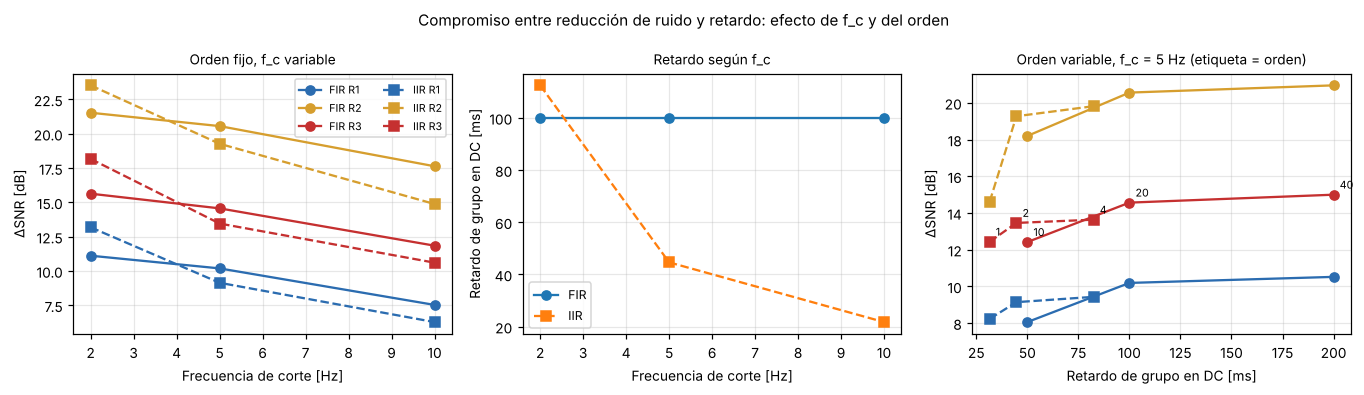

In [11]:
filas = []
for fc in sorted({FC, *FC_ALT}):
    tb, inf, _ = analizar(fc)
    for nom in ("FIR", "IIR"):
        fila = {"f_c [Hz]": fc, "Filtro": nom, "Retardo DC [ms]": inf[nom]["ret_teo"] * 1e3}
        for r in REGISTROS:
            fr = tb.set_index("Registro").loc[r]
            fila[f"ΔSNR {r} [dB]"] = fr[f"ΔSNR {nom} [dB]"]
            fila[f"Δmedia {r} [mg]"] = fr[f"Δmedia {nom} [mg]"]
        filas.append(fila)
tabla_sens = pd.DataFrame(filas)
print(tabla_sens.to_string(index=False))
tabla_sens.to_csv(SALIDA / "tabla_sensibilidad_fc.csv", index=False, float_format="%.4f")

filas = []
for nom, ordenes in (("FIR", [10, 20, 40]), ("IIR", [1, 2, 4])):
    for orden in ordenes:
        if nom == "FIR":
            b, a = signal.firwin(orden + 1, FC, window=VENTANA, fs=FS), np.array([1.0])
        else:
            b, a = signal.butter(orden, FC, btype="low", fs=FS)
        _, gd0 = signal.group_delay((b, a), w=[0.05], fs=FS)
        polos = np.roots(a)
        fila = {"Filtro": nom, "Orden": orden, "Coef.": len(b) + len(a) - 1,
                "Retardo DC [ms]": gd0[0] / FS * 1e3,
                "|p| máx": 0.0 if nom == "FIR" else float(np.max(np.abs(polos))),
                "Estable": bool(np.all(np.abs(polos) < 1))}
        for r in REGISTROS:
            y = signal.lfilter(b, a, X[r])
            fila[f"ΔSNR {r} [dB]"] = snr_db(y[K0:]) - snr_db(X[r][K0:])
        filas.append(fila)
tabla_orden = pd.DataFrame(filas)
print("\nSensibilidad al orden (f_c = 5 Hz):")
print(tabla_orden.to_string(index=False))
tabla_orden.to_csv(SALIDA / "tabla_sensibilidad_orden.csv", index=False, float_format="%.4f")

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.6))
for nom, ls in (("FIR", "-o"), ("IIR", "--s")):
    s = tabla_sens[tabla_sens["Filtro"] == nom]
    for r in REGISTROS:
        ax[0].plot(s["f_c [Hz]"], s[f"ΔSNR {r} [dB]"], ls, color=colores[r], label=f"{nom} {r}")
    ax[1].plot(s["f_c [Hz]"], s["Retardo DC [ms]"], ls, label=nom)
    o = tabla_orden[tabla_orden["Filtro"] == nom]
    for r in REGISTROS:
        ax[2].plot(o["Retardo DC [ms]"], o[f"ΔSNR {r} [dB]"], ls, color=colores[r], label=f"{nom} {r}")
    for _, f in o.iterrows():
        ax[2].annotate(f"{int(f['Orden'])}", (f["Retardo DC [ms]"], f[f"ΔSNR R3 [dB]"]),
                       textcoords="offset points", xytext=(4, 4), fontsize=7)
ax[2].set_xlabel("Retardo de grupo en DC [ms]"); ax[2].set_ylabel("ΔSNR [dB]")
ax[2].set_title("Orden variable, f_c = 5 Hz (etiqueta = orden)", fontsize=9)
ax[0].set_xlabel("Frecuencia de corte [Hz]"); ax[0].set_ylabel("ΔSNR [dB]"); ax[0].legend(fontsize=7, ncol=2)
ax[1].set_xlabel("Frecuencia de corte [Hz]"); ax[1].set_ylabel("Retardo de grupo en DC [ms]"); ax[1].legend(fontsize=8)
ax[0].set_title("Orden fijo, f_c variable", fontsize=9)
ax[1].set_title("Retardo según f_c", fontsize=9)
fig.suptitle("Compromiso entre reducción de ruido y retardo: efecto de f_c y del orden", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "fig9_sensibilidad_fc.png"); plt.show()

In [12]:
ruta_inc = DATOS / "INCLINACION.csv"
if ruta_inc.exists():
    df_inc, _ = leer_csv(ruta_inc)
    xi = df_inc[f"{EJE}_raw"].to_numpy(float) / LSB_POR_G
    ti = np.arange(xi.size) / FS
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(ti, xi, color="0.6", lw=0.8, label="entrada")
    for nom, d in INFO.items():
        yi = signal.lfilter(d["b"], d["a"], xi)
        ax.plot(ti, yi, lw=1.2, label=f"{nom} (xcorr: {retardo_xcorr(xi[K0:], yi[K0:]) * 1e3:.0f} ms)")
    ax.set_xlabel("t [s]"); ax.set_ylabel("a [g]"); ax.legend(fontsize=8)
    ax.set_title("Inclinación lenta: retardo observado")
    fig.tight_layout(); fig.savefig(SALIDA / "fig10_inclinacion.png"); plt.show()
else:
    print("No hay INCLINACION.csv (opcional).")

No hay INCLINACION.csv (opcional).


In [13]:
fr = tabla.set_index("Registro")
print("RESUMEN")
print(f"fs = {FS:g} Hz, eje {EJE}, f_c = {FC} Hz, descarte = {T_DESCARTE} s")
for r in REGISTROS:
    mejor = "FIR" if fr.loc[r, "ΔSNR FIR [dB]"] > fr.loc[r, "ΔSNR IIR [dB]"] else "IIR"
    print(f"{r} ({REGISTROS[r]}): SNR_in = {fr.loc[r, 'SNR ent. [dB]']:.2f} dB | "
          f"ΔSNR FIR = {fr.loc[r, 'ΔSNR FIR [dB]']:+.2f} dB | ΔSNR IIR = {fr.loc[r, 'ΔSNR IIR [dB]']:+.2f} dB "
          f"| mayor mejora: {mejor} | Δmedia FIR/IIR = {fr.loc[r, 'Δmedia FIR [mg]']:+.3f}/"
          f"{fr.loc[r, 'Δmedia IIR [mg]']:+.3f} mg")
print(f"Retardo DC: FIR {INFO['FIR']['ret_teo'] * 1e3:.1f} ms (constante, fase lineal) | "
      f"IIR {INFO['IIR']['ret_teo'] * 1e3:.1f} ms (varía con f)")
print(f"Multiplicaciones por muestra: FIR {INFO['FIR']['mult_por_muestra']} | IIR {INFO['IIR']['mult_por_muestra']}")
print(f"Polos IIR: |p| = {np.abs(np.roots(A_IIR))[0]:.4f} < 1 -> estable")
print("Figuras y tablas guardadas en:", SALIDA)

RESUMEN
fs = 100 Hz, eje az, f_c = 5.0 Hz, descarte = 1.0 s
R1 (Motor apagado): SNR_in = 54.54 dB | ΔSNR FIR = +10.19 dB | ΔSNR IIR = +9.14 dB | mayor mejora: FIR | Δmedia FIR/IIR = -0.004/-0.004 mg
R2 (Perturbación baja): SNR_in = 29.67 dB | ΔSNR FIR = +20.56 dB | ΔSNR IIR = +19.27 dB | mayor mejora: FIR | Δmedia FIR/IIR = +0.039/+0.025 mg
R3 (Perturbación alta): SNR_in = 31.46 dB | ΔSNR FIR = +14.56 dB | ΔSNR IIR = +13.46 dB | mayor mejora: FIR | Δmedia FIR/IIR = -0.004/-0.019 mg
Retardo DC: FIR 100.0 ms (constante, fase lineal) | IIR 44.6 ms (varía con f)
Multiplicaciones por muestra: FIR 21 | IIR 5
Polos IIR: |p| = 0.8008 < 1 -> estable
Figuras y tablas guardadas en: /home/claude/PDS_Proyecto2/resultados
